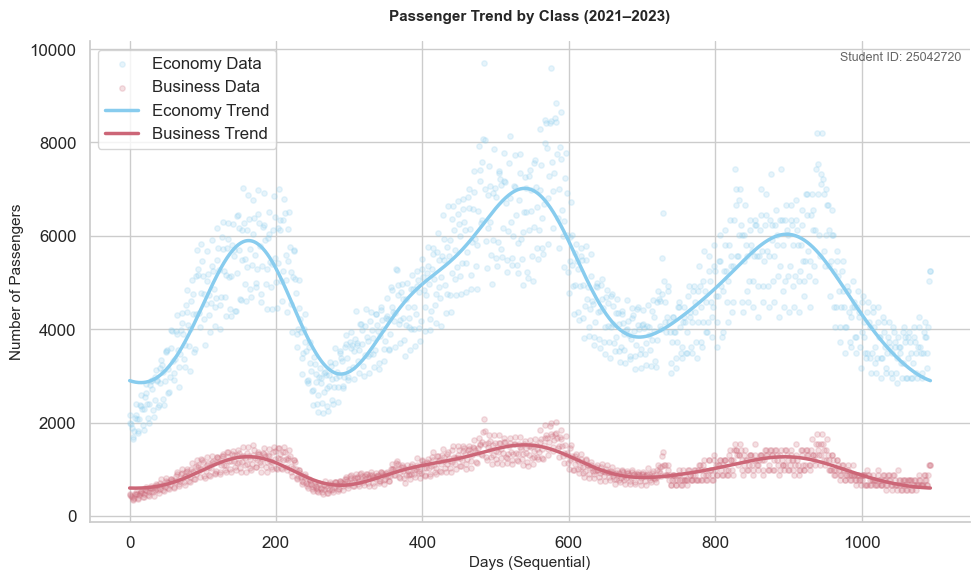

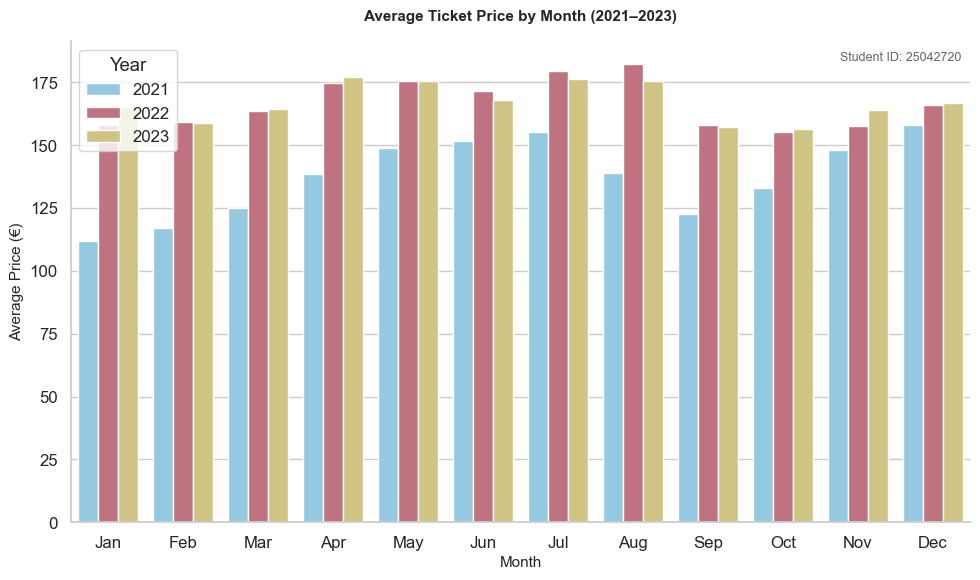

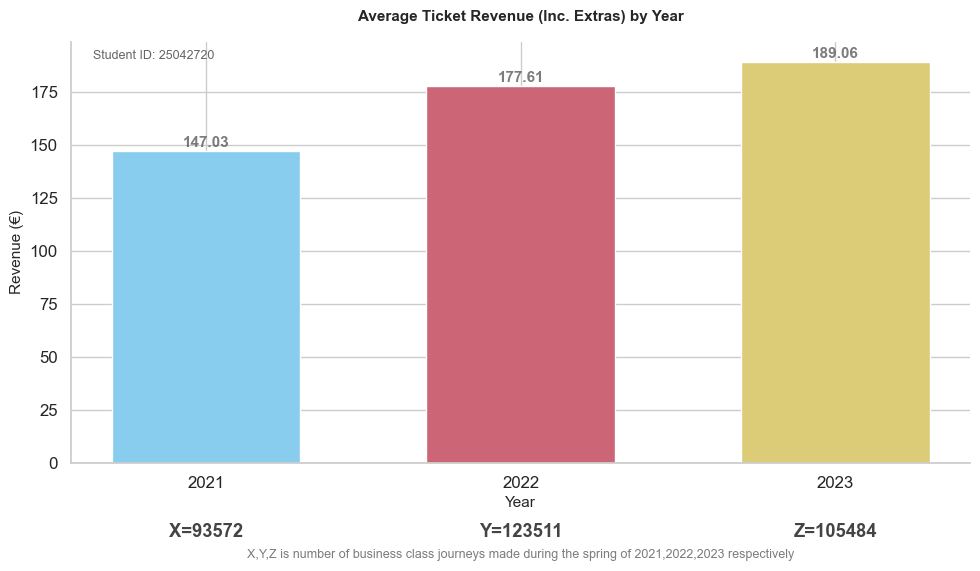

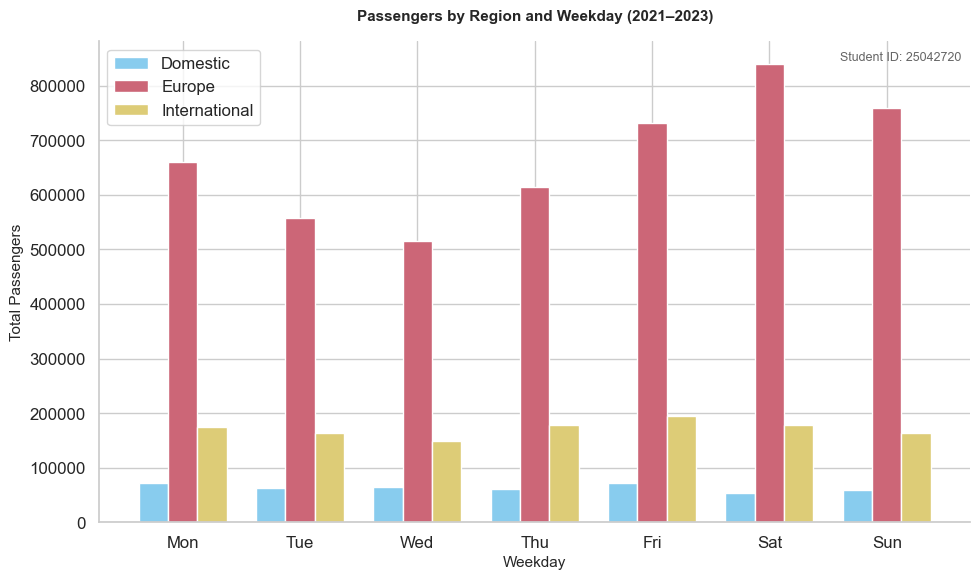

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scrfft

# ---------------- FIGURE 1 ----------------
def passenger_vs_class():
    df_23 = df_2023.groupby(['Date','Class'])['Class'].count().unstack().fillna(0) * SCALE
    df_23['Economy'] = df_23.get('Y', 0)
    df_23['Business'] = df_23.get('J', 0)

    df_2021_22['Economy'] = df_2021_22[['Pax Dom STD','Pax Eur STD','Pax Int STD']].sum(axis=1)
    df_2021_22['Business'] = df_2021_22[['Pax Dom BUS','Pax Eur BUS','Pax Int BUS']].sum(axis=1)

    df = pd.concat([
        df_2021_22[['Economy','Business']],
        df_23[['Economy','Business']].reset_index(drop=True)
    ]).reset_index(drop=True)

    df['Days'] = np.arange(len(df))
    x = df['Days'].to_numpy()

    def fft_smooth(y):
        freq, ccos, csin = scrfft.scrfft(x, y.to_numpy())
        y_pred = np.zeros_like(x, dtype=float)
        for f, c, s in zip(freq[:7], ccos[:7], csin[:7]):
            y_pred += c*np.cos(2*np.pi*f*x) + s*np.sin(2*np.pi*f*x)
        return y_pred

    plt.figure(figsize=(10, 6))
    
    # Scatter points with transparency (alpha) so the trend lines pop
    plt.scatter(x, df['Economy'], label='Economy Data', alpha=0.2, color=CORPORATE_PALETTE[0], s=15)
    plt.scatter(x, df['Business'], label='Business Data', alpha=0.2, color=CORPORATE_PALETTE[1], s=15)

    # Thick trend lines
    plt.plot(x, fft_smooth(df['Economy']), color=CORPORATE_PALETTE[0], linewidth=2.5, label='Economy Trend')
    plt.plot(x, fft_smooth(df['Business']), color=CORPORATE_PALETTE[1], linewidth=2.5, label='Business Trend')

    plt.title('Passenger Trend by Class (2021–2023)',fontsize=11, fontweight='bold', pad=15)
    plt.xlabel('Days (Sequential)',fontsize=11)
    plt.ylabel('Number of Passengers',fontsize=11)
    plt.legend(frameon=True)
    plt.text(0.99, 0.96, 'Student ID: 25042720', transform=plt.gca().transAxes, ha='right', fontsize=9, alpha=0.7)
    sns.despine()
    plt.savefig('figure1_passenger_trend.png', dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

# ---------------- FIGURE 2 ----------------
def avgprice_by_months():
    df_23 = df_2023.groupby(['Year','Month'])['Price'].mean().reset_index(name='Avg_price')

    df_2021_22['Dom'] = df_2021_22[['Pax Dom STD','Pax Dom BUS']].sum(axis=1)
    df_2021_22['Eur'] = df_2021_22[['Pax Eur STD','Pax Eur BUS']].sum(axis=1)
    df_2021_22['Int'] = df_2021_22[['Pax Int STD','Pax Int BUS']].sum(axis=1)

    df_2021_22['Revenue']=0
    cols = ['Price Dom STD','Price Dom BUS','Price Eur STD','Price Eur BUS','Price Int STD','Price Int BUS']
    pax_cols =['Pax Dom STD','Pax Dom BUS','Pax Eur STD','Pax Eur BUS','Pax Int STD','Pax Int BUS']
    for i in range(len(cols)):
        Total= (df_2021_22[cols[i]])*(df_2021_22[pax_cols[i]])
        df_2021_22['Revenue'] += Total
    df_2021_22['T_price']=df_2021_22['Revenue']/(df_2021_22['Dom']+ df_2021_22['Eur'] + df_2021_22['Int'])
    
    df_21_22 = df_2021_22.groupby(['Year','Month'])['T_price'].mean().reset_index(name='Avg_price')

    df = pd.concat([df_21_22, df_23])

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(data=df, x='Month', y='Avg_price', hue='Year',palette=CORPORATE_PALETTE[:3])

    plt.title('Average Ticket Price by Month (2021–2023)',fontsize=11, fontweight='bold', pad=15)
    plt.xticks(range(12), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
    plt.ylabel('Average Price (€)',fontsize=11)
    plt.xlabel('Month',fontsize=11)
    
    plt.text(0.99, 0.96, 'Student ID: 25042720', transform=plt.gca().transAxes, ha='right', fontsize=9, alpha=0.7)
    sns.despine()
    plt.tight_layout()
    plt.savefig('figure2_avg_price.png', dpi=300, bbox_inches='tight')
    plt.show()

# ---------------- FIGURE 3 ----------------
def avgrevenue_by_year():
    df_2023['Total_price'] = (df_2023['Price'] + df_2023['Extra'])

    pax_cols = ['Pax Dom STD','Pax Dom BUS','Pax Eur STD','Pax Eur BUS','Pax Int STD','Pax Int BUS']
    df_2021_22['Extra_per_pax'] = df_2021_22['AS revenue'] / df_2021_22[pax_cols].sum(axis=1)
    df_2021_22['Total_price'] = df_2021_22['T_price'] + df_2021_22['Extra_per_pax']

    yearly_avg = pd.concat([
        df_2021_22.groupby('Year')['Total_price'].mean(),
        df_2023.groupby('Year')['Total_price'].mean()
    ]).reindex([2021,2022,2023])

    spring = [3,4,5]
    df_2021_22['Business'] = df_2021_22[['Pax Dom BUS','Pax Eur BUS','Pax Int BUS']].sum(axis=1)
    spring_21_22 = df_2021_22[df_2021_22['Month'].isin(spring)].groupby('Year')['Business'].sum()
    spring_23 = df_2023[(df_2023['Month'].isin(spring)) & (df_2023['Class']=='J')].groupby('Year').size() * SCALE

    X, Y, Z = pd.concat([spring_21_22, spring_23]).reindex([2021,2022,2023]).fillna(0)

    plt.figure(figsize=(10, 6))
    bars = plt.bar(['2021','2022','2023'], yearly_avg.fillna(0), color=CORPORATE_PALETTE[:3], width=0.6)

    for bar, val in zip(bars, yearly_avg.fillna(0)):
        plt.text(bar.get_x() + bar.get_width()/2,  bar.get_height()+2,
                 f'{val:.2f}', ha='center', fontweight='bold', color='#444444',alpha=0.7,fontsize=11)
    
    for bar, lab, val in zip(bars, ['X','Y','Z'], [X,Y,Z]):
        plt.text(bar.get_x() + bar.get_width()/2,  -35,
                 f'{lab}={int(val)}', ha='center', fontweight='bold', color='#444444')
        
    plt.text(1 ,-45,'X,Y,Z is number of business class journeys made during the spring of 2021,2022,2023 respectively',
                 ha='center', color='#444444',fontsize=9,alpha=0.7)

    plt.title('Average Ticket Revenue (Inc. Extras) by Year',fontsize=11, fontweight='bold', pad=15)
    plt.xlabel('Year',fontsize=11)
    plt.ylabel('Revenue (€)',fontsize=11)
    plt.text(0.16, 0.96, 'Student ID: 25042720', transform=plt.gca().transAxes, ha='right', fontsize=9, alpha=0.7)
    sns.despine()
    plt.tight_layout()
    plt.savefig('figure3_annual_revenue.png', dpi=300, bbox_inches='tight')
    plt.show()

# ---------------- FIGURE 4 ----------------
def passenger_by_week():
    df_2023['Weekday'] = df_2023['Date'].dt.weekday
    df_2021_22['Weekday'] = df_2021_22['Date'].dt.weekday
    
    results = {}
    for r in ['Dom','Eur','Int']:
        base = df_2021_22.pivot_table(index='Weekday', values=r, columns='Year', aggfunc='sum')
        extra = df_2023[df_2023['Region']==r].pivot_table(index='Weekday', values='Region', columns='Year', aggfunc='count') * SCALE
        df_combined = base.merge(extra, on='Weekday', how='left')
        results[r] = df_combined.sum(axis=1)

    x = np.arange(7)
    plt.figure(figsize=(10, 6))

    plt.bar(x - 0.25, results['Dom'], width=0.25, label='Domestic', color=CORPORATE_PALETTE[0])
    plt.bar(x,        results['Eur'], width=0.25, label='Europe', color=CORPORATE_PALETTE[1])
    plt.bar(x + 0.25, results['Int'], width=0.25, label='International', color=CORPORATE_PALETTE[2])

    plt.title('Passengers by Region and Weekday (2021–2023)',fontsize=11, fontweight='bold', pad=15)
    plt.xticks(x, ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
    plt.xlabel('Weekday',fontsize=11)
    plt.ylabel('Total Passengers',fontsize=11)
    plt.legend()
    plt.text(0.99, 0.96, 'Student ID: 25042720', transform=plt.gca().transAxes, ha='right', fontsize=9, alpha=0.7)
    sns.despine()
    plt.tight_layout()
    plt.savefig('figure4_weekday_region.png', dpi=300, bbox_inches='tight')
    plt.show()

def main():
    sns.set_theme(style="whitegrid", font_scale=1.1)
    CORPORATE_PALETTE = ["#88CCEE", "#CC6677", "#DDCC77", "#117733", "#332288"]
    sns.set_palette(CORPORATE_PALETTE)
    
    SCALE = 109.31  
    
    # Load and Preprocess
    df_2021_22 = pd.read_csv('twoyeardata2.csv')
    df_2023 = pd.read_csv('2023dataset2.csv')
    
    for df in [df_2021_22, df_2023]:
        df['Date'] = pd.to_datetime(df['Date'])
        df['Month'] = df['Date'].dt.month
        df['Year'] = df['Date'].dt.year

    passenger_vs_class()
    avgprice_by_months()
    avgrevenue_by_year()
    passenger_by_week()

if __name__ == '__main__':
    main()

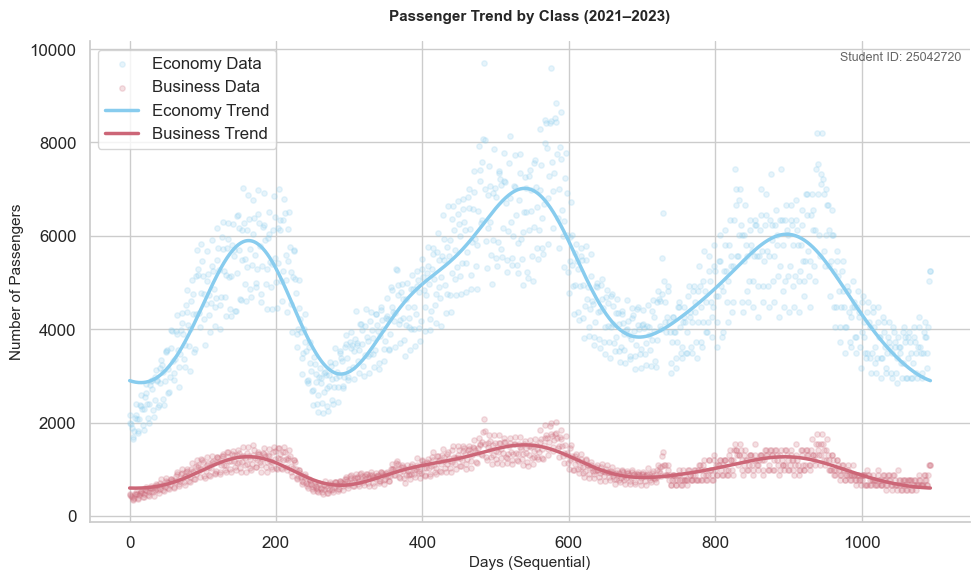

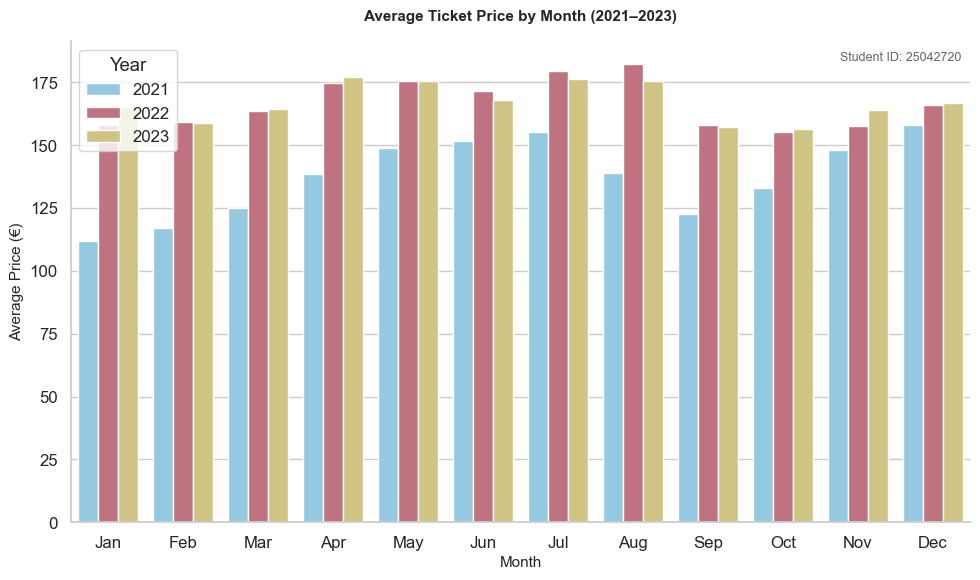

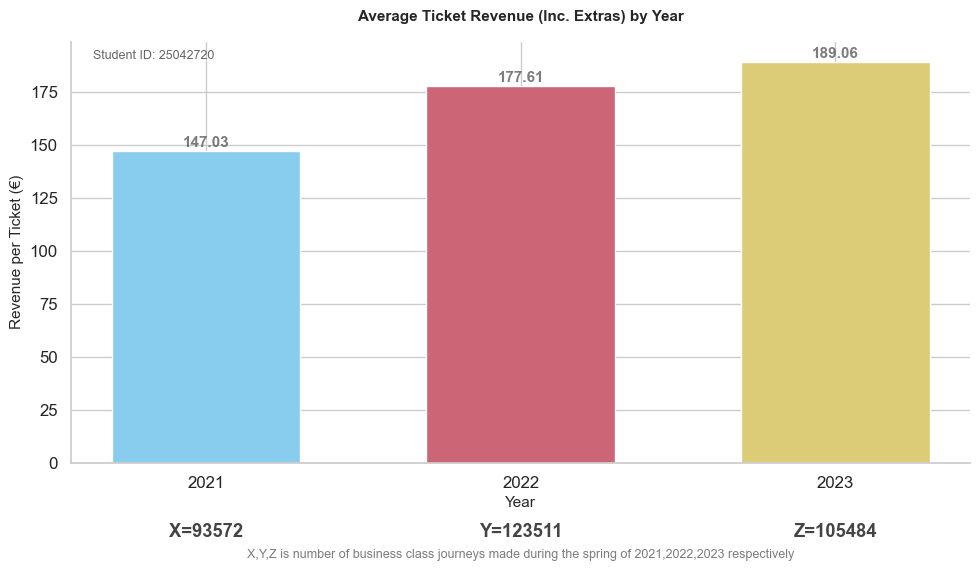

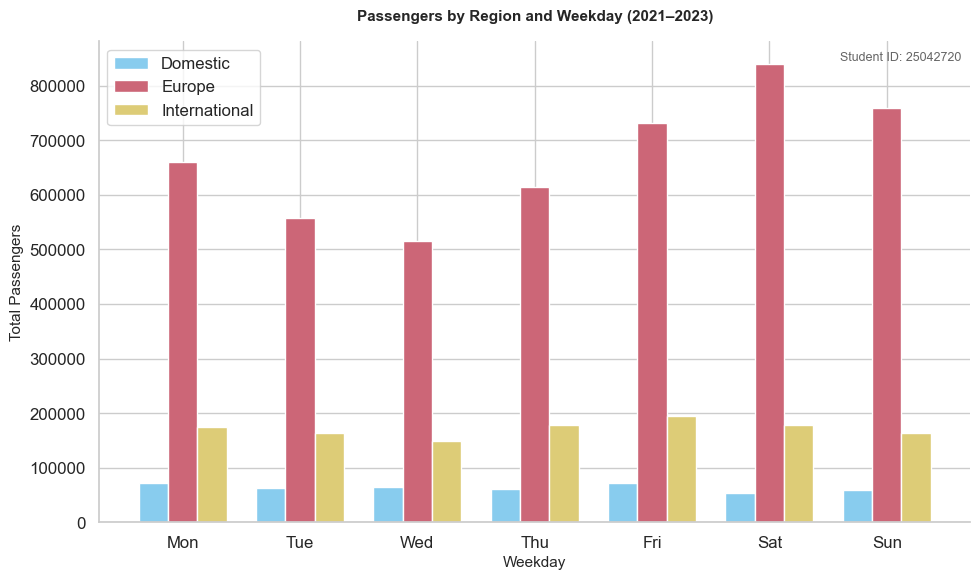

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scrfft


# ---------------- FIGURE 1 ----------------
def passenger_vs_class():
    """
    Plot passenger trends for Economy vs Business class (2021–2023)
    using FFT smoothing for trend lines.
    """

    # Aggregate 2023 data by date and class
    df_23 = (
        df_2023.groupby(['Date', 'Class'])['Class']
        .count()
        .unstack()
        .fillna(0) * SCALE
    )

    df_23['Economy'] = df_23.get('Y', 0)
    df_23['Business'] = df_23.get('J', 0)

    # Combine standard and business passengers for earlier dataset
    df_2021_22['Economy'] = df_2021_22[
        ['Pax Dom STD', 'Pax Eur STD', 'Pax Int STD']
    ].sum(axis=1)

    df_2021_22['Business'] = df_2021_22[
        ['Pax Dom BUS', 'Pax Eur BUS', 'Pax Int BUS']
    ].sum(axis=1)

    # Merge datasets
    df = pd.concat([
        df_2021_22[['Economy', 'Business']],
        df_23[['Economy', 'Business']].reset_index(drop=True)
    ]).reset_index(drop=True)

    # Create sequential day index
    df['Days'] = np.arange(len(df))
    x = df['Days'].to_numpy()

    def fft_smooth(y):
        """Apply FFT smoothing using first 7 frequency components."""
        freq, ccos, csin = scrfft.scrfft(x, y.to_numpy())
        y_pred = np.zeros_like(x, dtype=float)

        for f, c, s in zip(freq[:7], ccos[:7], csin[:7]):
            y_pred += c * np.cos(2 * np.pi * f * x) + s * np.sin(2 * np.pi * f * x)

        return y_pred

    plt.figure(figsize=(10, 6))

    # Scatter plot of raw data
    plt.scatter(
        x, df['Economy'],
        label='Economy Data',
        alpha=0.2,
        color=CORPORATE_PALETTE[0],
        s=15
    )

    plt.scatter(
        x, df['Business'],
        label='Business Data',
        alpha=0.2,
        color=CORPORATE_PALETTE[1],
        s=15
    )

    # Smoothed trend lines
    plt.plot(
        x, fft_smooth(df['Economy']),
        color=CORPORATE_PALETTE[0],
        linewidth=2.5,
        label='Economy Trend'
    )

    plt.plot(
        x, fft_smooth(df['Business']),
        color=CORPORATE_PALETTE[1],
        linewidth=2.5,
        label='Business Trend'
    )

    # Labels and formatting
    plt.title('Passenger Trend by Class (2021–2023)',
              fontsize=11, fontweight='bold', pad=15)
    plt.xlabel('Days (Sequential)', fontsize=11)
    plt.ylabel('Number of Passengers', fontsize=11)
    plt.legend(frameon=True)

    plt.text(
        0.99, 0.96,
        'Student ID: 25042720',
        transform=plt.gca().transAxes,
        ha='right',
        fontsize=9,
        alpha=0.7
    )

    sns.despine()
    plt.savefig('figure1_passenger_trend.png',
                dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()


# ---------------- FIGURE 2 ----------------
def avgprice_by_months():
    """
    Plot average ticket price per month for 2021–2023.
    """

    # Average price for 2023
    df_23 = (
        df_2023.groupby(['Year', 'Month'])['Price']
        .mean()
        .reset_index(name='Avg_price')
    )

    # Total passengers per region
    df_2021_22['Dom'] = df_2021_22[
        ['Pax Dom STD', 'Pax Dom BUS']
    ].sum(axis=1)

    df_2021_22['Eur'] = df_2021_22[
        ['Pax Eur STD', 'Pax Eur BUS']
    ].sum(axis=1)

    df_2021_22['Int'] = df_2021_22[
        ['Pax Int STD', 'Pax Int BUS']
    ].sum(axis=1)

    # Calculate total revenue
    df_2021_22['Revenue'] = 0

    cols = [
        'Price Dom STD', 'Price Dom BUS',
        'Price Eur STD', 'Price Eur BUS',
        'Price Int STD', 'Price Int BUS'
    ]

    pax_cols = [
        'Pax Dom STD', 'Pax Dom BUS',
        'Pax Eur STD', 'Pax Eur BUS',
        'Pax Int STD', 'Pax Int BUS'
    ]

    for i in range(len(cols)):
        total = df_2021_22[cols[i]] * df_2021_22[pax_cols[i]]
        df_2021_22['Revenue'] += total

    # Average ticket price
    df_2021_22['T_price'] = (
        df_2021_22['Revenue'] /
        (df_2021_22['Dom'] + df_2021_22['Eur'] + df_2021_22['Int'])
    )

    df_21_22 = (
        df_2021_22.groupby(['Year', 'Month'])['T_price']
        .mean()
        .reset_index(name='Avg_price')
    )

    # Combine datasets
    df = pd.concat([df_21_22, df_23])

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=df,
        x='Month',
        y='Avg_price',
        hue='Year',
        palette=CORPORATE_PALETTE[:3]
    )

    # Labels and formatting
    plt.title('Average Ticket Price by Month (2021–2023)',
              fontsize=11, fontweight='bold', pad=15)

    plt.xticks(
        range(12),
        ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
         'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    )

    plt.ylabel('Average Price (€)', fontsize=11)
    plt.xlabel('Month', fontsize=11)

    plt.text(
        0.99, 0.96,
        'Student ID: 25042720',
        transform=plt.gca().transAxes,
        ha='right',
        fontsize=9,
        alpha=0.7
    )

    sns.despine()
    plt.tight_layout()
    plt.savefig('figure2_avg_price.png',
                dpi=300, bbox_inches='tight')
    plt.show()


# ---------------- FIGURE 3 ----------------
def avgrevenue_by_year():
    """
    Plot average yearly revenue including extras,
    and annotate business-class spring totals.
    """

    # Total price including extras for 2023
    df_2023['Total_price'] = df_2023['Price'] + df_2023['Extra']

    pax_cols = [
        'Pax Dom STD', 'Pax Dom BUS',
        'Pax Eur STD', 'Pax Eur BUS',
        'Pax Int STD', 'Pax Int BUS'
    ]

    # Extra revenue per passenger
    df_2021_22['Extra_per_pax'] = (
        df_2021_22['AS revenue'] /
        df_2021_22[pax_cols].sum(axis=1)
    )

    df_2021_22['Total_price'] = (
        df_2021_22['T_price'] + df_2021_22['Extra_per_pax']
    )

    # Yearly averages
    yearly_avg = pd.concat([
        df_2021_22.groupby('Year')['Total_price'].mean(),
        df_2023.groupby('Year')['Total_price'].mean()
    ]).reindex([2021, 2022, 2023])

    # Spring business passengers
    spring = [3, 4, 5]

    df_2021_22['Business'] = df_2021_22[
        ['Pax Dom BUS', 'Pax Eur BUS', 'Pax Int BUS']
    ].sum(axis=1)

    spring_21_22 = (
        df_2021_22[df_2021_22['Month'].isin(spring)]
        .groupby('Year')['Business']
        .sum()
    )

    spring_23 = (
        df_2023[
            (df_2023['Month'].isin(spring)) &
            (df_2023['Class'] == 'J')
        ]
        .groupby('Year')
        .size() * SCALE
    )

    X, Y, Z = pd.concat([spring_21_22, spring_23]) \
        .reindex([2021, 2022, 2023]) \
        .fillna(0)

    plt.figure(figsize=(10, 6))

    bars = plt.bar(
        ['2021', '2022', '2023'],
        yearly_avg.fillna(0),
        color=CORPORATE_PALETTE[:3],
        width=0.6
    )

    # Value labels on bars
    for bar, val in zip(bars, yearly_avg.fillna(0)):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f'{val:.2f}',
            ha='center',
            fontweight='bold',
            color='#444444',
            alpha=0.7,
            fontsize=11
        )

    # X, Y, Z labels (spring business passengers)
    for bar, lab, val in zip(bars, ['X', 'Y', 'Z'], [X, Y, Z]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            -35,
            f'{lab}={int(val)}',
            ha='center',
            fontweight='bold',
            color='#444444'
        )

    plt.text(
        1, -45,
        ('X,Y,Z is number of business class journeys made during '
         'the spring of 2021,2022,2023 respectively'),
        ha='center',
        color='#444444',
        fontsize=9,
        alpha=0.7
    )

    # Labels
    plt.title('Average Ticket Revenue (Inc. Extras) by Year',
              fontsize=11, fontweight='bold', pad=15)
    plt.xlabel('Year', fontsize=11)
    plt.ylabel('Revenue per Ticket (€)', fontsize=11)

    plt.text(
        0.16, 0.96,
        'Student ID: 25042720',
        transform=plt.gca().transAxes,
        ha='right',
        fontsize=9,
        alpha=0.7
    )

    sns.despine()
    plt.tight_layout()
    plt.savefig('figure3_annual_revenue.png',
                dpi=300, bbox_inches='tight')
    plt.show()


# ---------------- FIGURE 4 ----------------
def passenger_by_week():
    """
    Plot passenger counts by weekday and region (Dom, Eur, Int).
    """

    # Extract weekday
    df_2023['Weekday'] = df_2023['Date'].dt.weekday
    df_2021_22['Weekday'] = df_2021_22['Date'].dt.weekday

    results = {}

    # Process each region
    for region in ['Dom', 'Eur', 'Int']:
        base = df_2021_22.pivot_table(
            index='Weekday',
            values=region,
            columns='Year',
            aggfunc='sum'
        )

        extra = df_2023[df_2023['Region'] == region] \
            .pivot_table(
                index='Weekday',
                values='Region',
                columns='Year',
                aggfunc='count'
            ) * SCALE

        df_combined = base.merge(extra, on='Weekday', how='left')
        results[region] = df_combined.sum(axis=1)

    x = np.arange(7)
    plt.figure(figsize=(10, 6))

    # Bar plots
    plt.bar(
        x - 0.25, results['Dom'],
        width=0.25,
        label='Domestic',
        color=CORPORATE_PALETTE[0]
    )

    plt.bar(
        x, results['Eur'],
        width=0.25,
        label='Europe',
        color=CORPORATE_PALETTE[1]
    )

    plt.bar(
        x + 0.25, results['Int'],
        width=0.25,
        label='International',
        color=CORPORATE_PALETTE[2]
    )

    # Labels
    plt.title('Passengers by Region and Weekday (2021–2023)',
              fontsize=11, fontweight='bold', pad=15)

    plt.xticks(x, ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
    plt.xlabel('Weekday', fontsize=11)
    plt.ylabel('Total Passengers', fontsize=11)
    plt.legend()

    plt.text(
        0.99, 0.96,
        'Student ID: 25042720',
        transform=plt.gca().transAxes,
        ha='right',
        fontsize=9,
        alpha=0.7
    )

    sns.despine()
    plt.tight_layout()
    plt.savefig('figure4_weekday_region.png',
                dpi=300, bbox_inches='tight')
    plt.show()


def main():
    """
    Main execution function:
    - Sets plotting style
    - Loads datasets
    - Preprocesses data
    - Calls all visualisation functions
    """

    sns.set_theme(style="whitegrid", font_scale=1.1)

    global CORPORATE_PALETTE
    CORPORATE_PALETTE = [
        "#88CCEE", "#CC6677", "#DDCC77",
        "#117733", "#332288"
    ]
    sns.set_palette(CORPORATE_PALETTE)

    global SCALE
    SCALE = 109.31

    # Load datasets
    global df_2021_22, df_2023
    df_2021_22 = pd.read_csv('twoyeardata2.csv')
    df_2023 = pd.read_csv('2023dataset2.csv')

    # Convert date columns
    for df in [df_2021_22, df_2023]:
        df['Date'] = pd.to_datetime(df['Date'])
        df['Month'] = df['Date'].dt.month
        df['Year'] = df['Date'].dt.year

    # Generate all figures
    passenger_vs_class()
    avgprice_by_months()
    avgrevenue_by_year()
    passenger_by_week()


if __name__ == '__main__':
    main()